**ANOMALY DETECTION OC-SVM**

In [11]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [12]:
versioni = dh.get_artifact_versions("moco_2D_metrics_net_v5", project="floods")
for v in sorted(versioni, key=lambda v: v.metadata.created):
    print(v.id, v.metadata.created)

fecf7148756c464e807dd3b6bca5db75 2026-10-26T15:40:51.646Z
124199cc3e54463282baecd5a7299e28 2026-10-26T15:40:58.883Z
4d1f5bfeefca433cb6bceee7dcd50d5d 2026-10-26T15:41:06.081Z
2f0a1a73799b4b44aa5f72053370f7b4 2026-10-26T16:39:47.287Z
f8becd3c5b5e433e8fb2864bc778f330 2026-10-26T17:02:43.681Z
bd525ad7d09e45b8a34a56fdad8a92d5 2026-10-26T17:22:49.423Z
2c14c0449d2c4f34bfd09afd1cf1bd85 2026-10-26T17:42:59.87Z
3c6d0ee7c67d47cf96d62ba5926f4893 2026-10-26T18:03:09.301Z
a0287c5ac07a4aa0b107ee06906f1c13 2026-10-26T18:23:18.721Z
64c00adefac2444c9a1b45d90020db77 2026-10-26T18:43:35.191Z
bb68e2152734447bb3118726b1d480fd 2026-10-26T19:03:46.654Z
d47aeb4ef4b04c4098f86c9a9101b493 2026-10-26T19:23:57.919Z
43e9e08b2f9b4acba5bfce791c3d3073 2026-10-26T19:44:12.01Z
62927cee1a544756a391a1a0ef76d358 2026-10-26T20:04:26.254Z
b14bbd54b9ef4219b5a99a7a7e1e0469 2026-10-26T20:26:04.968Z
50f93483cd584c9a98a6dac15446231e 2026-10-26T20:46:44.686Z
70a1b1490495441bb9fb0e8784398097 2026-10-26T21:07:23.132Z
b6645a136d6c4684

In [13]:
versioni = dh.get_artifact_versions("moco_2D_weights_net_v5", project="floods")
for v in sorted(versioni, key=lambda v: v.metadata.created):
    print(v.id, v.metadata.created)

e17bfd61a70e47a5af530fe441cbf570 2026-10-26T15:40:53.061Z
9b272602720242d9ab0bc1a6d5c57b25 2026-10-26T15:41:00.306Z
88ce11eb0ff24a3da3e90cb280a0c976 2026-10-26T16:39:48.879Z
cc701bb74f42455ebbbcf9d45b56872c 2026-10-26T17:02:45.098Z
accaab6a8f6a4be49e95db801030caf6 2026-10-26T17:22:50.861Z
9be8c58108524d37868fa26197a9a9d2 2026-10-26T17:43:01.717Z
7472d641b4b44792a90d92f2fa84377f 2026-10-26T18:03:10.809Z
1db6080006f04953bcbdb66fbc863d9d 2026-10-26T18:23:20.254Z
2095783603e844b890490aa8160a38fd 2026-10-26T18:43:36.626Z
c154a2b2275d4495a8cba473f893510e 2026-10-26T19:23:59.796Z
5236faf54a104a03b4148443fcdbc736 2026-10-26T19:44:13.699Z
8bf5f7e62602485ab3a58ae606ed968f 2026-10-26T20:26:06.722Z
9ccf57b762264d468e2a6fd400e21fb9 2026-10-26T21:07:24.468Z
2a3758c4658a49cda22a8e36af3f6d6b 2026-10-26T22:09:09.036Z
9c23c3ba8e8242d085097848abb63250 2026-10-26T22:50:26.234Z
6a0eccc320284a7084d28f5341541516 2026-10-27T00:33:22.746Z
9baf5e5af0694bd5b9bc2013a8b32be2 2026-10-27T00:53:58.228Z
0ca782a60e3849

**SETUP PARAMETERS**

In [2]:
job_name = "net_v5_bn0_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v5_bn0"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False,                 
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                       # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,

    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                      # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [3]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all3',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm3",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-03 09:51:37,285 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...


2026-11-03 09:51:42,292 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:51:47,301 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:51:52,312 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:51:57,327 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:52:02,335 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:52:07,348 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09:52:12,360 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0158ca99a9c14864a55cf25feb6b7194 to finish...
2026-11-03 09

In [3]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           # una cartella per job
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              # solo i punti calcolati in questa run
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          # punto -> (results, df), per i grafici
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

# confronto tra i punti
print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: net_v5_bn0_0per | moco: net_v5_bn0 | punti: encoder, pre_proj, proj_raw, post_proj 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.020932043212037024
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.051
min_flood_area = 0.000
score normali: 18.2486 ± 17.5966
score anomale: -2.4566 ± 15.8435
AUROC: 0.803


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-16.204117,598.0,81.0,1804.0,2321.0,0.033722,0.751041,0.248959,0.880707,0.388186
FA 10%,-9.198974,967.0,202.0,1435.0,2200.0,0.084097,0.597419,0.402581,0.827203,0.541585
FA 15%,-3.925811,1231.0,310.0,1171.0,2092.0,0.129059,0.487510,0.512490,0.798832,0.624398
FA 20%,0.689589,1441.0,428.0,961.0,1974.0,0.178185,0.400083,0.599917,0.771001,0.674783
FA 25%,4.440649,1601.0,556.0,801.0,1846.0,0.231474,0.333472,0.666528,0.742235,0.702347
FA 30%,7.545300,1720.0,666.0,682.0,1736.0,0.277269,0.283930,0.716070,0.720872,0.718463


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.015034312986188394
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.049
min_flood_area = 0.000
score normali: 11.1617 ± 7.3349
score anomale: 4.4001 ± 6.6108
AUROC: 0.751


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-2.865582,380.0,88.0,2022.0,2314.0,0.036636,0.841799,0.158201,0.811966,0.264808
FA 10%,-0.502618,690.0,207.0,1712.0,2195.0,0.086178,0.712739,0.287261,0.769231,0.418309
FA 15%,1.762295,1002.0,323.0,1400.0,2079.0,0.134471,0.582848,0.417152,0.756226,0.537698
FA 20%,3.417394,1203.0,412.0,1199.0,1990.0,0.171524,0.499167,0.500833,0.744892,0.598954
FA 25%,5.210433,1398.0,555.0,1004.0,1847.0,0.231057,0.417985,0.582015,0.715822,0.642021
FA 30%,6.803322,1558.0,682.0,844.0,1720.0,0.283930,0.351374,0.648626,0.695536,0.671262


===== post_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.0028344639013280276
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: -3.1998 ± 14.0003
score anomale: -8.9531 ± 15.0490
AUROC: 0.611


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-25.690447,327.0,110.0,2075.0,2292.0,0.045795,0.863863,0.136137,0.748284,0.230363
FA 10%,-21.046331,526.0,234.0,1876.0,2168.0,0.097419,0.781016,0.218984,0.692105,0.332701
FA 15%,-17.661875,708.0,374.0,1694.0,2028.0,0.155704,0.705246,0.294754,0.654344,0.406429
FA 20%,-15.456487,820.0,463.0,1582.0,1939.0,0.192756,0.658618,0.341382,0.639127,0.445047
FA 25%,-12.888022,974.0,614.0,1428.0,1788.0,0.255620,0.594505,0.405495,0.613350,0.488221
FA 30%,-10.726733,1118.0,749.0,1284.0,1653.0,0.311823,0.534555,0.465445,0.598822,0.523776


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.021,0.803
proj_raw,256,0.015,0.751
post_proj,256,0.003,0.611


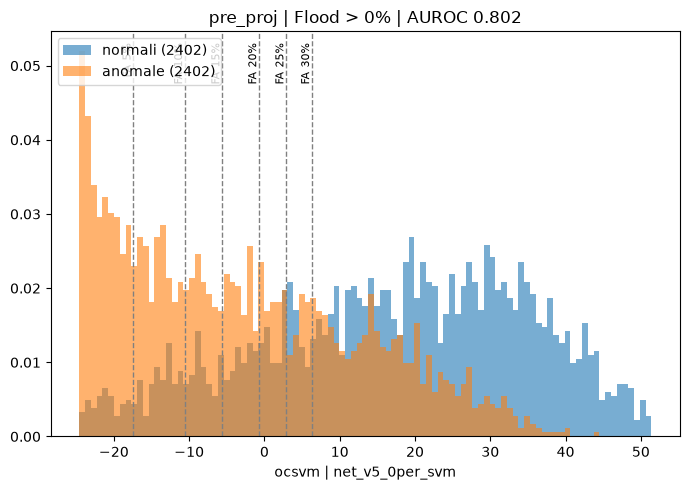

In [ ]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

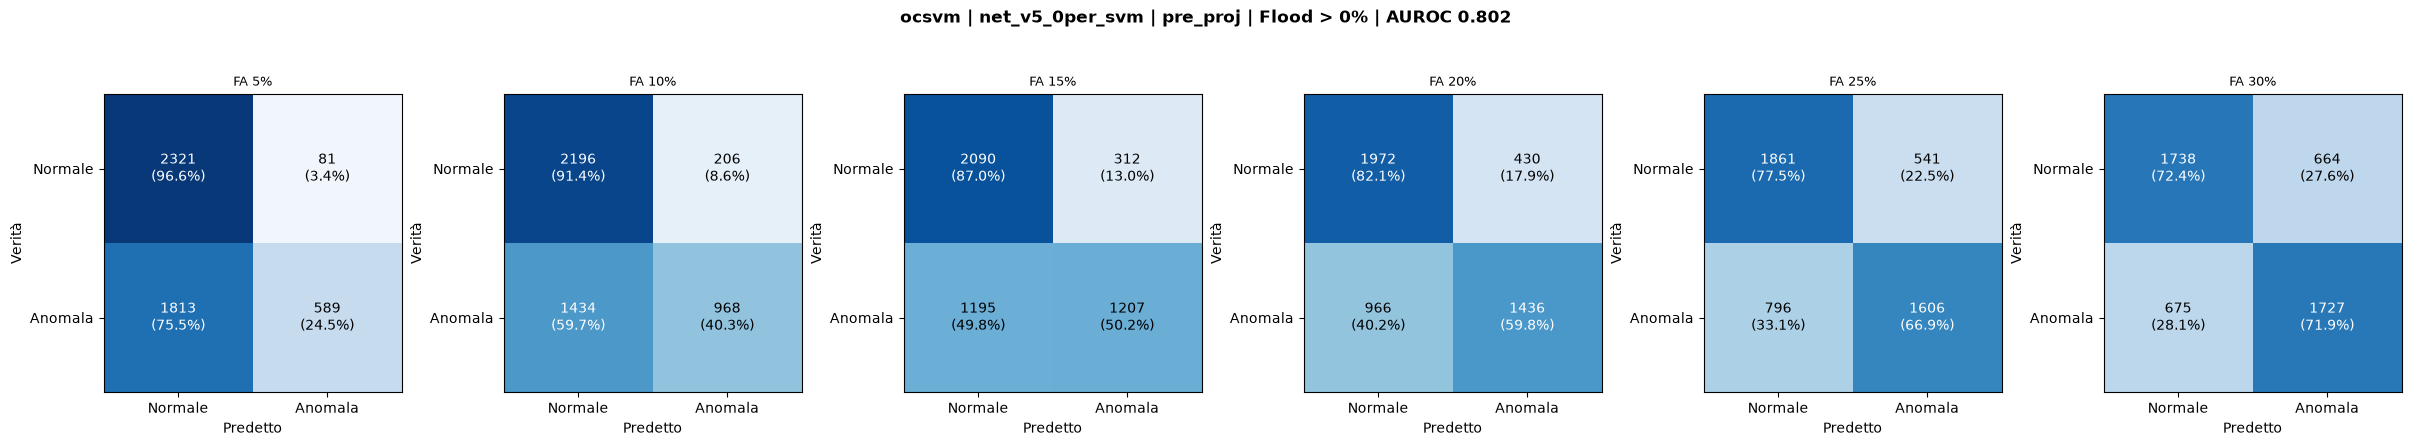

In [ ]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "encoder"

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                    
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}          
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC validazione": auroc(md, n_val, a_val),                
    })

lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC validazione": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_net_v5_bn0_0per
job:           net_v5_bn0_0per | moco: net_v5_bn0 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj
punto:         encoder | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.855 (ocsvm, whitening lw, 512 componenti) 

forme: {'fit': (19893, 512), 'thr': (2572, 512), 'normal': (2402, 512), 'anom': (2402, 512)} 

Ledoit-Wolf shrinkage: 0.002
          thr/fit  AUROC validazione
k                                   
32          1.058              0.686
64          1.034              0.744
128         1.025              0.780
256         1.026              0.822
512         1.050              0.853
LW (512)    1.050              0.853


In [7]:
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

def carica(results_dir, punto):
    E = np.load(f"{results_dir}/{punto}/embeddings.npz")
    return {g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)
            for g in ("fit", "normal", "anom")}

enc = carica(RESULTS_DIR, "encoder")
pre = carica(RESULTS_DIR, "pre_proj")
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]

def md_lw(w):
    sc = StandardScaler().fit(w["fit"])
    w = {g: sc.transform(v) for g, v in w.items()}
    lw = LedoitWolf().fit(w["fit"])
    return {g: lw.mahalanobis(v) for g, v in w.items()}

s_enc = md_lw(enc)
s_pre = md_lw(pre)
s_cat = md_lw({g: np.concatenate([enc[g], pre[g]], axis=1) for g in enc})

from scipy.stats import rankdata
r = lambda s: rankdata(np.r_[s["normal"], s["anom"]]) / (len(s["normal"]) + len(s["anom"]))
s_fus = (r(s_enc) + r(s_pre)) / 2

for nome, s in (("encoder", np.r_[s_enc["normal"], s_enc["anom"]]),
                ("pre_proj", np.r_[s_pre["normal"], s_pre["anom"]]),
                ("encoder + pre_proj (concatenati)", np.r_[s_cat["normal"], s_cat["anom"]]),
                ("encoder + pre_proj (media dei ranghi)", s_fus)):
    print(f"{nome:38s}: AUROC {roc_auc_score(y, s):.3f}")

encoder                               : AUROC 0.855
pre_proj                              : AUROC 0.803
encoder + pre_proj (concatenati)      : AUROC 0.814
encoder + pre_proj (media dei ranghi) : AUROC 0.851


In [9]:
from scipy.stats import spearmanr

tutti_enc = np.r_[s_enc["normal"], s_enc["anom"]]
tutti_pre = np.r_[s_pre["normal"], s_pre["anom"]]
print(f"correlazione di Spearman tra gli score: {spearmanr(tutti_enc, tutti_pre).correlation:.3f}")

correlazione di Spearman tra gli score: 0.775


In [10]:
from scipy.stats import spearmanr

fa = 0.10                                                   

enc = carica(RESULTS_DIR, "encoder")
s_enc = md_lw(enc)
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]
tutti = lambda s: np.r_[s["normal"], s["anom"]]

def rilevate(s):
    soglia = np.quantile(s["normal"], 1 - fa)
    return s["anom"] > soglia

righe = []
for punto in ("pre_proj", "proj_raw", "post_proj"):
    print(f"--- {punto} ---", flush=True)
    altro = carica(RESULTS_DIR, punto)
    s_alt = md_lw(altro)
    s_cat = md_lw({g: np.concatenate([enc[g], altro[g]], axis=1) for g in enc})

    r_enc, r_alt = rilevate(s_enc), rilevate(s_alt)
    righe.append({
        "punto": punto,
        "AUROC punto": roc_auc_score(y, tutti(s_alt)),
        "concatenati": roc_auc_score(y, tutti(s_cat)),
        "media ranghi": roc_auc_score(y, (r(s_enc) + r(s_alt)) / 2),
        "massimo ranghi": roc_auc_score(y, np.maximum(r(s_enc), r(s_alt))),
        "Spearman": spearmanr(tutti(s_enc), tutti(s_alt)).correlation,
        "solo encoder": np.mean(r_enc & ~r_alt),
        "solo punto": np.mean(~r_enc & r_alt),
    })

print(f"\nencoder da solo: AUROC {roc_auc_score(y, tutti(s_enc)):.3f}")
pd.DataFrame(righe).set_index("punto").round(3)

--- pre_proj ---
--- proj_raw ---
--- post_proj ---

encoder da solo: AUROC 0.855


,AUROC punto,concatenati,media ranghi,massimo ranghi,Spearman,solo encoder,solo punto
punto,,,,,,,
pre_proj,0.803,0.814,0.851,0.838,0.775,0.206,0.047
proj_raw,0.750,0.855,0.835,0.813,0.637,0.328,0.050
post_proj,0.630,0.855,0.789,0.770,0.408,0.411,0.044
